O objetivo é encontrar uma definicação ideal apra o formato dos superpixel, que vão virar os nós da rede

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.segmentation import slic, mark_boundaries
import glob
import numpy as np
import pandas as pd
from skimage.color import rgb2gray
from skimage.feature import canny
from skimage.segmentation import slic, find_boundaries
from scipy.ndimage import distance_transform_edt

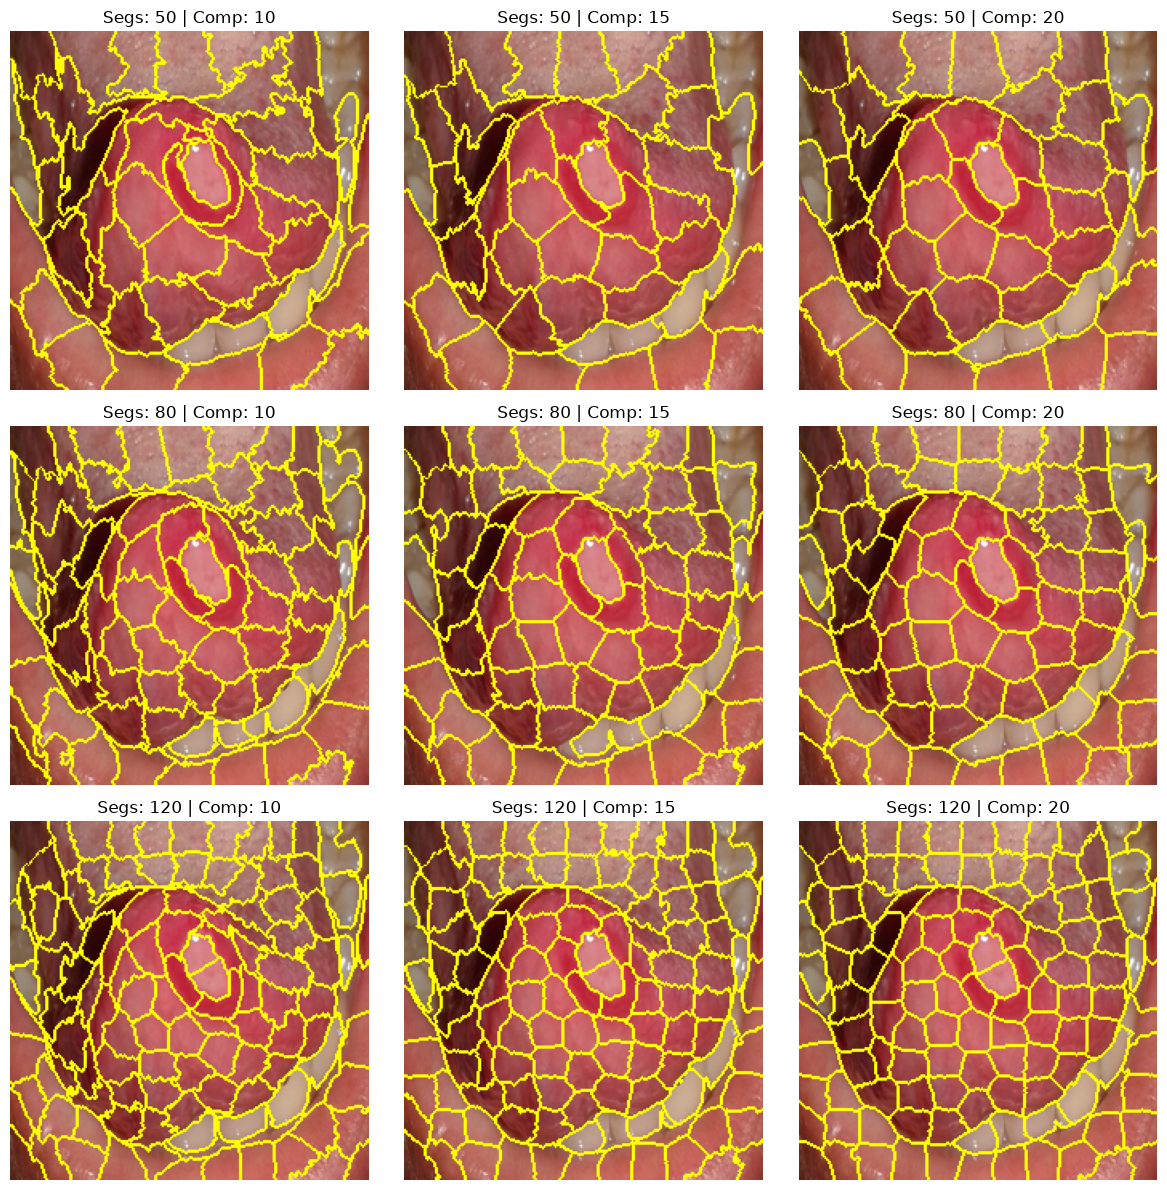

In [7]:
# Função para carregar a imagem e redimensionar para o padrão combinado com o Luiz
def carregar_imagem(caminho):
    img = Image.open(caminho).convert("RGB").resize((224, 224))
    return np.array(img)


#  Exemplo com a benigna

caminho_img = "../data/original_data/benign_lesions/1.jpg" 
img_np = carregar_imagem(caminho_img)

# Testando diferentes granularidades e formatos
n_segments_list = [50, 80, 120]
compactness_list = [10, 15, 20]

fig, axes = plt.subplots(len(n_segments_list), len(compactness_list), figsize=(12, 12))

for i, n_seg in enumerate(n_segments_list):
    for j, comp in enumerate(compactness_list):
        # start_label=0 é vital para mapearmos os IDs dos nós de 0 a N amanhã
        segments = slic(img_np, n_segments=n_seg, compactness=comp, start_label=0)
        
        ax = axes[i, j]
        ax.imshow(mark_boundaries(img_np, segments))
        ax.set_title(f"Segs: {n_seg} | Comp: {comp}")
        ax.axis("off")

plt.tight_layout()
plt.show()

O melhor visaulmente foi o Segs 80 e Comp 15

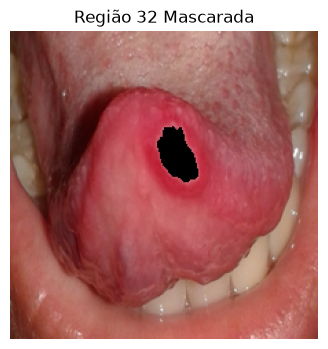

In [8]:
# Gerando a segmentação final com os parâmetros escolhidos
segments_final = slic(img_np, n_segments=80, compactness=15, start_label=0)

# Mapeamento região -> pixels (coração da nossa perturbação)
num_nodes = segments_final.max() + 1
regiao_para_pixels = {node_id: np.where(segments_final == node_id) for node_id in range(num_nodes)}

# Copia a imagem original para mascarar
img_mascarada = img_np.copy()

# Escolhendo uma região arbitrária para desligar (ex: id 15)
id_regiao = 32
img_mascarada[regiao_para_pixels[id_regiao]] = [0, 0, 0] # Pinta de preto

# Visualiza o resultado
plt.figure(figsize=(4, 4))
plt.imshow(img_mascarada)
plt.title(f"Região {id_regiao} Mascarada")
plt.axis("off")
plt.show()

In [9]:
def boundary_recall(img_np: np.ndarray, segments: np.ndarray, tol: int = 2) -> float:
    """Calcula a fração de bordas (Canny) cobertas pelas fronteiras SLIC dentro de `tol` pixels."""
    gray = rgb2gray(img_np)
    ref_edges = canny(gray, sigma=1.5)
    if not np.any(ref_edges):
        return 0.0
    
    slic_bounds = find_boundaries(segments, mode="thick")
    # Distância de cada pixel até a fronteira SLIC mais próxima
    dist_to_slic = distance_transform_edt(~slic_bounds)
    
    matched_edges = ref_edges & (dist_to_slic <= tol)
    return float(matched_edges.sum() / ref_edges.sum())

# Amostra de 10 imagens (5 benignas, 5 malignas) para calibrar os hiperparâmetros
amostras = (
    sorted(glob.glob("../data/original_data/benign_lesions/*.jpg"))[:5] +
    sorted(glob.glob("../data/original_data/malignant_lesions/*.jpg"))[:5]
)

resultados = []
for n_seg in [40, 70, 100]:
    for comp in [5, 10, 20]:
        recalls, nos_reais = [], []
        for path in amostras:
            img = np.asarray(Image.open(path).convert("RGB").resize((224, 224)), dtype=np.float32) / 255.0
            segs = slic(img, n_segments=n_seg, compactness=comp, start_label=0)
            recalls.append(boundary_recall(img, segs, tol=2))
            nos_reais.append(int(segs.max() + 1))
            
        resultados.append({
            "n_segments": n_seg,
            "compactness": comp,
            "nos_medios": round(np.mean(nos_reais), 1),
            "boundary_recall_mean": round(np.mean(recalls), 4),
            "boundary_recall_std": round(np.std(recalls), 4),
        })

df_slic = pd.DataFrame(resultados)
display(df_slic)

,n_segments,compactness,nos_medios,boundary_recall_mean,boundary_recall_std
0,40,5,27.5,0.5098,0.0739
1,40,10,33.0,0.5353,0.0708
2,40,20,35.5,0.4587,0.0547
3,70,5,50.5,0.6306,0.0788
4,70,10,57.5,0.6258,0.0511
5,70,20,62.3,0.5318,0.0492
6,100,5,79.2,0.6932,0.0720
7,100,10,91.7,0.7134,0.0479
8,100,20,98.3,0.6237,0.0439


 (70, 10): Tem uma média de 57,5 nós e um boundary recall de 0.6258 ($\pm 0.0511$). É um grafo bem enxuto e rápido de processar na API, mas deixa escapar cerca de 37% das bordas de referência

 (100, 20): Tem uma média de 98,3 nós e um boundary recall de 0.6237 ($\pm 0.0439$).

In [10]:
N_SEGMENTS, COMPACTNESS= 70, 10 

In [11]:
import sys
import importlib
sys.path.append("..")  # garante que o Python encontre a pasta src/

import src.explainability
importlib.reload(src.explainability)

import torch
import matplotlib.pyplot as plt
from PIL import Image
from src.modelo_treinado import CNN
from src.explainability import SuperpixelGraphExplainer
import importlib
import src.modelo_treinado
importlib.reload(src.modelo_treinado)
from src.modelo_treinado import CNNLightning


model = CNNLightning.load_from_checkpoint("../models/cnn_geral.ckpt", map_location="cpu")
explainer = SuperpixelGraphExplainer(model, n_segments=70, compactness=10, num_samples=150)

amostras_visuais = [
    
    ("Benigno 1", "../data/augmented_data/augmented_benign/1.jpg"),
    ("Benigno 2", "../data/augmented_data/augmented_benign/2.jpg"),
    ("Maligno 1", "../data/augmented_data/augmented_malignant/1.jpg"),
    ("Maligno 2", "../data/augmented_data/augmented_malignant/2.jpg"),
]


/home/jaimewillian/Documentos/FGV/6P/DL 2/api-oncolens/.env/lib/python3.14/site-packages/lightning/pytorch/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.5.5, which is newer than your current Lightning version: v2.4.0


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

def plotar_e_definir_cortes(y_true, y_prob, recall_alvo=0.98):
    # precision_recall_curve retorna thresholds em ordem crescente;
    # precision e recall têm 1 elemento a mais que thresholds
    prec, rec, thresholds = precision_recall_curve(y_true, y_prob)
    prec_t = prec[:-1]
    rec_t = rec[:-1]

    # Calcula F1 para cada limiar avaliado
    f1_t = np.where(
        (prec_t + rec_t) > 0,
        2 * (prec_t * rec_t) / (prec_t + rec_t),
        0.0
    )

    # 1. t_baixo: maior limiar que ainda mantém recall >= recall_alvo (evita FN)
    idx_rec = np.where(rec_t >= recall_alvo)[0]
    if len(idx_rec) > 0:
        # Escolhe o maior limiar dentro da meta de recall para não jogar benignos demais em dúvida
        best_i_baixo = idx_rec[np.argmax(thresholds[idx_rec])]
        t_baixo = float(thresholds[best_i_baixo])
    else:
        t_baixo = float(thresholds[np.argmax(rec_t)])

    # 2. t_alto: limiar que maximiza o F1-score (garantindo que fique acima de t_baixo)
    mask_alto = thresholds > t_baixo
    if np.any(mask_alto):
        idx_candidates = np.where(mask_alto)[0]
        best_i_alto = idx_candidates[np.argmax(f1_t[idx_candidates])]
        t_alto = float(thresholds[best_i_alto])
    else:
        t_alto = min(float(t_baixo + 0.15), 0.90)

    # Plot das curvas Precision e Recall em função do limiar
    plt.figure(figsize=(9, 5))
    plt.plot(thresholds, prec_t, label="Precision (classe Maligno)", linewidth=2)
    plt.plot(thresholds, rec_t, label="Recall (classe Maligno)", linewidth=2)
    plt.plot(thresholds, f1_t, label="F1-score", linestyle="--", alpha=0.8)

    plt.axvline(t_baixo, color="green", linestyle=":", linewidth=2, label=f"t_baixo = {t_baixo:.3f}")
    plt.axvline(t_alto, color="red", linestyle=":", linewidth=2, label=f"t_alto = {t_alto:.3f}")

    plt.axvspan(0.0, t_baixo, color="green", alpha=0.06)
    plt.axvspan(t_baixo, t_alto, color="orange", alpha=0.08)
    plt.axvspan(t_alto, 1.0, color="red", alpha=0.06)

    plt.title("Precision, Recall e F1 em função do limiar (Validação)")
    plt.xlabel("Limiar de probabilidade")
    plt.ylabel("Pontuação")
    plt.xlim(0.0, 1.0)
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    return t_baixo, t_alto

def classificar_tres_faixas(prob, t_baixo, t_alto):
    if prob >= t_alto:
        return "Maligno"
    elif prob >= t_baixo:
        return "Inconclusivo"
    else:
        return "Benigno"

# Exemplo de uso:
# t_baixo, t_alto = plotar_e_definir_cortes(y_true_val, y_prob_val, recall_alvo=0.98)
# print(f"Faixas: Benigno < {t_baixo:.3f} | Inconclusivo [{t_baixo:.3f}, {t_alto:.3f}) | Maligno >= {t_alto:.3f}")

Total de imagens carregadas: 323 (Benigno: 165 | Maligno: 158)


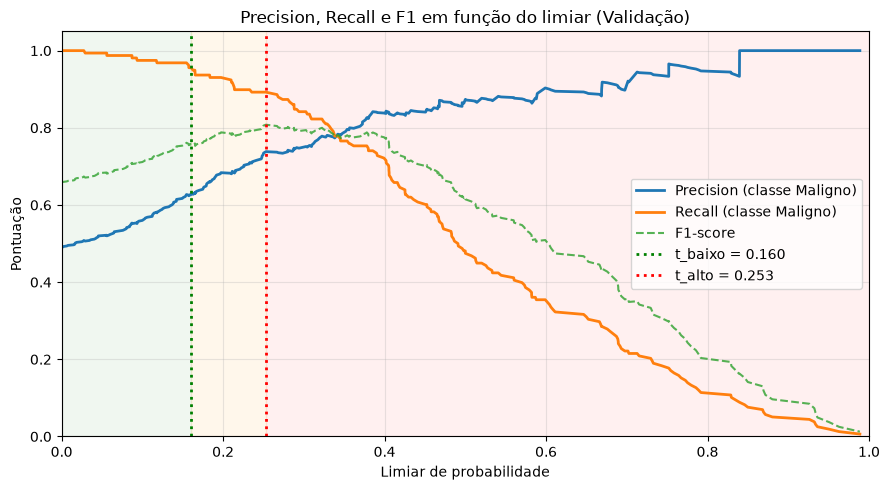


Limiares sugeridos -> Benigno < 0.160 | Inconclusivo [0.160, 0.253) | Maligno >= 0.253

Recall (não-Benigno / proteção contra FN): 0.9557
Falsos Negativos (Malignos classificados como Benigno): 7
Precision (Maligno direto >= t_alto): 0.7382


Previsto,Benigno,Inconclusivo,Maligno,All
Real,,,,
Benigno (Real),76,39,50,165
Maligno (Real),7,10,141,158
All,83,49,191,323


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import recall_score, precision_score

# 1. Ajuste os caminhos das pastas do seu dataset (validação ou original_data)
PASTA_BENIGNO = Path("../data/original_data/benign_lesions")      # rótulo 0
PASTA_MALIGNO = Path("../data/original_data/malignant_lesions")   # rótulo 1

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

amostras = (
    [(p, 0) for p in PASTA_BENIGNO.rglob("*") if p.suffix.lower() in EXTS]
    + [(p, 1) for p in PASTA_MALIGNO.rglob("*") if p.suffix.lower() in EXTS]
)
print(f"Total de imagens carregadas: {len(amostras)} "
      f"(Benigno: {sum(y == 0 for _, y in amostras)} | Maligno: {sum(y == 1 for _, y in amostras)})")

# 2. Dataset e DataLoader com o mesmo tamanho de entrada do modelo/explainer
W, H = explainer.input_width, explainer.input_height  # ex: 304 x 304

transform = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    # Descomente a linha abaixo se o seu CNNLightning foi treinado com normalização ImageNet:
    # transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class OralDataset(Dataset):
    def __init__(self, itens, tfm):
        self.itens = itens
        self.tfm = tfm

    def __len__(self):
        return len(self.itens)

    def __getitem__(self, idx):
        caminho, label = self.itens[idx]
        img = Image.open(caminho).convert("RGB")
        return self.tfm(img), label

loader = DataLoader(OralDataset(amostras, transform), batch_size=32, shuffle=False)

# 3. Inferência em lote para extrair y_true_val e y_prob_val
device = next(model.parameters()).device
model.eval()

y_true_list, y_prob_list = [], []

with torch.no_grad():
    for x, y in loader:
        x = x.to(device)
        out = model(x)

        # Trata saída com 1 logit (BCE) ou 2 logits (CrossEntropy)
        if out.ndim == 2 and out.shape[1] == 2:
            probs = torch.softmax(out, dim=1)[:, 1]
        else:
            # Se o forward() do seu modelo já aplicar sigmoid, troque por: probs = out.view(-1)
            probs = probs = out.view(-1)
        y_prob_list.append(probs.cpu().numpy())
        y_true_list.append(y.numpy())

y_true_val = np.concatenate(y_true_list)
y_prob_val = np.concatenate(y_prob_list)

# 4. Define os cortes pela curva PR (usando a função plotar_e_definir_cortes da célula anterior)
t_baixo, t_alto = plotar_e_definir_cortes(y_true_val, y_prob_val, recall_alvo=0.95)
print(f"\nLimiares sugeridos -> Benigno < {t_baixo:.3f} | Inconclusivo [{t_baixo:.3f}, {t_alto:.3f}) | Maligno >= {t_alto:.3f}")

# 5. Avalia a classificação em 3 faixas no dataset
faixas_val = np.array([classificar_tres_faixas(p, t_baixo, t_alto) for p in y_prob_val])

# Proteção contra falsos negativos: tudo que NÃO caiu em "Benigno" vai para revisão/alerta
nao_benigno_pred = (y_prob_val >= t_baixo).astype(int)
maligno_direto_pred = (y_prob_val >= t_alto).astype(int)

fn_benigno = int(((y_true_val == 1) & (faixas_val == "Benigno")).sum())

print(f"\nRecall (não-Benigno / proteção contra FN): {recall_score(y_true_val, nao_benigno_pred):.4f}")
print(f"Falsos Negativos (Malignos classificados como Benigno): {fn_benigno}")
print(f"Precision (Maligno direto >= t_alto): {precision_score(y_true_val, maligno_direto_pred, zero_division=0):.4f}")

# Tabela cruzada: Classe Real x Faixa Prevista
tabela = pd.crosstab(
    pd.Series(np.where(y_true_val == 1, "Maligno (Real)", "Benigno (Real)"), name="Real"),
    pd.Series(faixas_val, name="Previsto"),
    margins=True
)
display(tabela)

In [14]:
import inspect

print("=== Hiperparâmetros do modelo ===")
print(model.hparams)

print("\n=== Código do SuperpixelGraphExplainer ===")
print(inspect.getsource(explainer.__class__))

=== Hiperparâmetros do modelo ===
"activation_name": relu
"dropout":         0.11998429798463187
"input_channels":  3
"input_height":    304
"input_width":     304
"kernel_size":     3
"learning_rate":   0.00021168375865669698
"n_conv_layers":   3
"n_filters":       50
"num_classes":     1

=== Código do SuperpixelGraphExplainer ===
class SuperpixelGraphExplainer:
    def __init__(
        self,
        model: torch.nn.Module,
        n_segments: int = 70,
        compactness: float = 10.0,
        num_samples: int = 150,
        kernel_width: float = 0.25,
        device: str = "cpu",
        t_baixo: float = 0.160,
        t_alto: float = 0.253,
        decision_threshold: float | None = None,
    ):
        self.model = model.to(device)
        self.model.eval()
        self.n_segments = n_segments
        self.compactness = compactness
        self.num_samples = num_samples
        self.kernel_width = kernel_width
        self.device = device
        self.t_baixo = t_baixo
        

In [15]:
nome, caminho = amostras_visuais[-1]  # ex: Maligno 2
img = Image.open(caminho).convert("RGB")
prob_explainer = explainer.explain(img, seed=42)["probabilidade"]

W, H = explainer.input_width, explainer.input_height
device = next(model.parameters()).device
model.eval()

tfm_sem_norm = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
])

tfm_com_norm = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

with torch.no_grad():
    for rotulo, tfm in [("Sem Normalize", tfm_sem_norm), ("Com Normalize", tfm_com_norm)]:
        x = tfm(img).unsqueeze(0).to(device)
        out = model(x)
        prob_raw = out.view(-1).item()
        prob_sig = torch.sigmoid(out.view(-1)).item()
        print(f"{rotulo:15s} -> raw: {prob_raw:.4f} | com sigmoid: {prob_sig:.4f}")

print(f"Explainer       -> prob: {prob_explainer:.4f}")

Sem Normalize   -> raw: 0.6935 | com sigmoid: 0.6667
Com Normalize   -> raw: 1.0000 | com sigmoid: 0.7311
Explainer       -> prob: 0.6935


,precision_alvo,t_baixo,t_alto,FN_em_Benigno,FP_em_Maligno,qtd_Inconclusivo,pct_Inconclusivo,precision_Maligno,recall_nao_Benigno
0,0.75,0.16,0.303,7,44,63,19.5%,0.7514,0.9557
1,0.80,0.16,0.357,7,30,90,27.9%,0.8000,0.9557
2,0.85,0.16,0.461,7,16,132,40.9%,0.8519,0.9557
3,0.90,0.16,0.599,7,6,178,55.1%,0.9032,0.9557


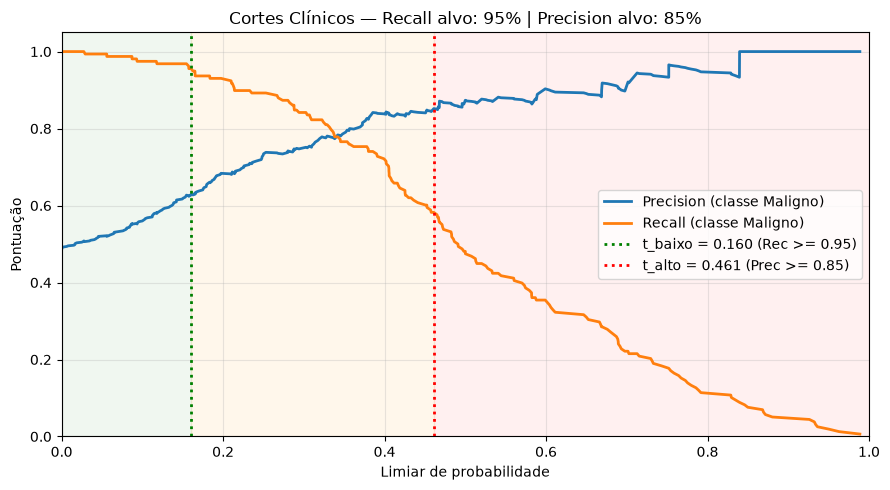

Previsto,Benigno,Inconclusivo,Maligno,All
Real,,,,
Benigno (Real),76,73,16,165
Maligno (Real),7,59,92,158
All,83,132,108,323


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, precision_score, recall_score

def definir_cortes_clinicos(y_true, y_prob, recall_alvo=0.95, precision_alvo=0.85, plotar=True):
    prec, rec, thresholds = precision_recall_curve(y_true, y_prob)
    prec_t, rec_t = prec[:-1], rec[:-1]

    # 1. t_baixo: maior limiar que ainda garante recall >= recall_alvo (evita FN)
    idx_rec = np.where(rec_t >= recall_alvo)[0]
    t_baixo = float(thresholds[idx_rec[-1]]) if len(idx_rec) > 0 else float(thresholds[np.argmax(rec_t)])

    # 2. t_alto: menor limiar (> t_baixo) que atinge precision >= precision_alvo
    idx_prec = np.where((thresholds > t_baixo) & (prec_t >= precision_alvo))[0]
    if len(idx_prec) > 0:
        t_alto = float(thresholds[idx_prec[0]])
    else:
        t_alto = float(thresholds[-1])

    faixas = np.where(
        y_prob >= t_alto, "Maligno",
        np.where(y_prob >= t_baixo, "Inconclusivo", "Benigno")
    )

    if plotar:
        plt.figure(figsize=(9, 5))
        plt.plot(thresholds, prec_t, label="Precision (classe Maligno)", linewidth=2)
        plt.plot(thresholds, rec_t, label="Recall (classe Maligno)", linewidth=2)
        plt.axvline(t_baixo, color="green", linestyle=":", linewidth=2, label=f"t_baixo = {t_baixo:.3f} (Rec >= {recall_alvo})")
        plt.axvline(t_alto, color="red", linestyle=":", linewidth=2, label=f"t_alto = {t_alto:.3f} (Prec >= {precision_alvo})")
        plt.axvspan(0.0, t_baixo, color="green", alpha=0.06)
        plt.axvspan(t_baixo, t_alto, color="orange", alpha=0.08)
        plt.axvspan(t_alto, 1.0, color="red", alpha=0.06)
        plt.title(f"Cortes Clínicos — Recall alvo: {recall_alvo:.0%} | Precision alvo: {precision_alvo:.0%}")
        plt.xlabel("Limiar de probabilidade")
        plt.ylabel("Pontuação")
        plt.xlim(0.0, 1.0)
        plt.ylim(0.0, 1.05)
        plt.grid(True, alpha=0.3)
        plt.legend(loc="best")
        plt.tight_layout()
        plt.show()

    return t_baixo, t_alto, faixas

# Compara cenários de Precision mínima para t_alto
resumo = []
for p_alvo in [0.75, 0.80, 0.85, 0.90]:
    tb, ta, fx = definir_cortes_clinicos(y_true_val, y_prob_val, recall_alvo=0.95, precision_alvo=p_alvo, plotar=False)
    resumo.append({
        "precision_alvo": p_alvo,
        "t_baixo": round(tb, 3),
        "t_alto": round(ta, 3),
        "FN_em_Benigno": int(((y_true_val == 1) & (fx == "Benigno")).sum()),
        "FP_em_Maligno": int(((y_true_val == 0) & (fx == "Maligno")).sum()),
        "qtd_Inconclusivo": int((fx == "Inconclusivo").sum()),
        "pct_Inconclusivo": f"{100 * (fx == 'Inconclusivo').mean():.1f}%",
        "precision_Maligno": round(precision_score(y_true_val, (y_prob_val >= ta).astype(int), zero_division=0), 4),
        "recall_nao_Benigno": round(recall_score(y_true_val, (y_prob_val >= tb).astype(int), zero_division=0), 4),
    })

display(pd.DataFrame(resumo))

# Plota e mostra a tabela cruzada detalhada para precision_alvo = 0.85
t_baixo, t_alto, faixas_val = definir_cortes_clinicos(y_true_val, y_prob_val, recall_alvo=0.95, precision_alvo=0.85, plotar=True)

tabela = pd.crosstab(
    pd.Series(np.where(y_true_val == 1, "Maligno (Real)", "Benigno (Real)"), name="Real"),
    pd.Series(faixas_val, name="Previsto"),
    margins=True
)
display(tabela)

In [17]:
t_baixo, t_alto

(0.16034185886383057, 0.460942804813385)

In [18]:
import importlib
import src.explainability
importlib.reload(src.explainability)

import time

device_eval = "cuda" if torch.cuda.is_available() else "cpu"
print("Rodando em:", device_eval)

explainer_dryad = src.explainability.SuperpixelGraphExplainer(
    model=model,
    n_segments=70,
    compactness=10,
    num_samples=150 if device_eval == "cuda" else 80,
    t_baixo=t_baixo,
    t_alto=t_alto,
    device=device_eval,
)

Rodando em: cpu


,Amostra,Probabilidade,Classificação,Nós,Arestas,Drop Top-5
0,Benigno 1,0.3085,Inconclusivo,60,156,0.0243
1,Benigno 2,0.3125,Inconclusivo,59,146,0.0692
2,Maligno 1,0.4055,Inconclusivo,54,135,0.1142
3,Maligno 2,0.6935,Maligno,57,142,0.0985


KeyboardInterrupt: 

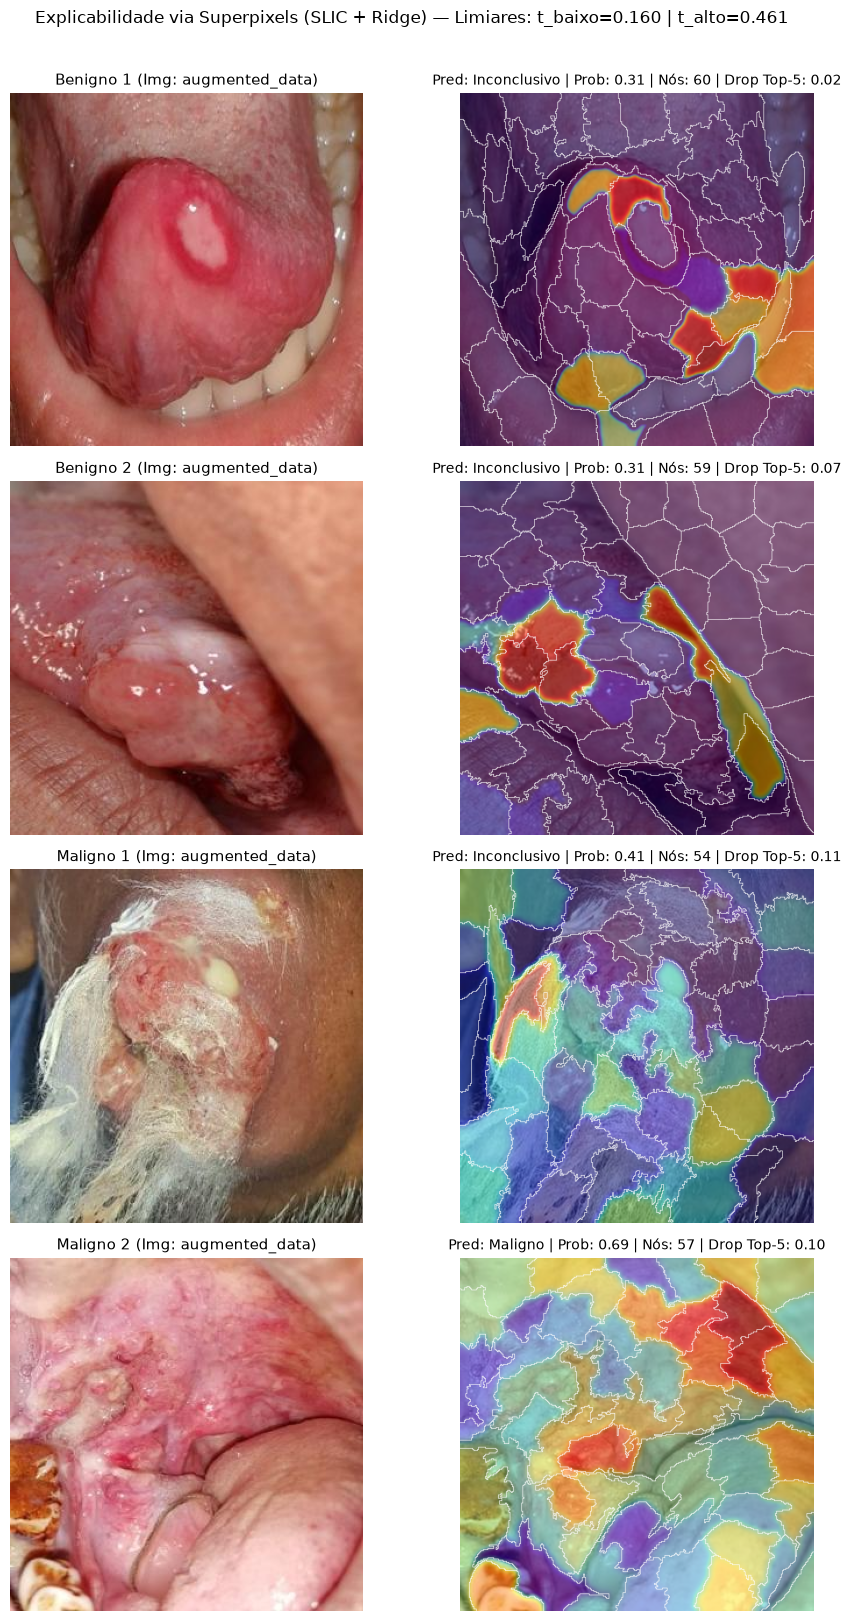

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

linhas = []
fig, axes = plt.subplots(len(amostras_visuais), 2, figsize=(10, 4 * len(amostras_visuais)))

for i, (nome, caminho) in enumerate(amostras_visuais):
    img_orig = Image.open(caminho).convert("RGB")
    resultado = explainer_dryad.explain(img_orig, seed=42)

    prob = resultado["probabilidade"]
    classificacao = resultado["classificacao"]
    n_nos = resultado["num_superpixels"]
    n_arestas = resultado["num_arestas"]
    drop_top5 = resultado["fidelity_drop_top5"]
    overlay = resultado["overlay_image"]

    # Monta os dados da tabela final
    linhas.append({
        "Amostra": nome,
        "Probabilidade": round(prob, 4),
        "Classificação": classificacao,
        "Nós": n_nos,
        "Arestas": n_arestas,
        "Drop Top-5": round(drop_top5, 4),
    })

    # Identifica a origem da imagem automaticamente pelo caminho
    origem_img = "augmented_data" if "augmented" in str(caminho) else "original_data"

    # Coluna da esquerda: Imagem de entrada
    axes[i, 0].imshow(img_orig)
    axes[i, 0].set_title(f"{nome} (Img: {origem_img})", fontsize=11)
    axes[i, 0].axis("off")

    # Coluna da direita: Overlay com a classificação calibrada
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title(
        f"Pred: {classificacao} | Prob: {prob:.2f} | Nós: {n_nos} | Drop Top-5: {drop_top5:.2f}",
        fontsize=10
    )
    axes[i, 1].axis("off")

# 1. Tabela final
df_resultados_finais = pd.DataFrame(linhas)
display(df_resultados_finais)

# 2. Painel visual atualizado
fig.suptitle(
    f"Explicabilidade via Superpixels (SLIC + Ridge) — Limiares: t_baixo={t_baixo:.3f} | t_alto={t_alto:.3f}",
    fontsize=12,
    y=1.01
)
plt.tight_layout()
plt.savefig("resultados_superpixels_overlay.png", dpi=200, bbox_inches="tight")
plt.show()

## Analise do dataset que possui as mascaras

images/: 243 | masks/: 185 | Pares exatos: 185
Valores únicos na 1ª máscara: [ 0  2  3  4  5  7 11 14 19 20]
Executando em cpu | 185 imagens | num_samples=80
[10/185] 31s decorridos | ETA: 538s
[20/185] 66s decorridos | ETA: 546s
[30/185] 105s decorridos | ETA: 540s
[40/185] 141s decorridos | ETA: 510s
[50/185] 178s decorridos | ETA: 479s
[60/185] 216s decorridos | ETA: 449s
[70/185] 252s decorridos | ETA: 414s
[80/185] 286s decorridos | ETA: 375s
[90/185] 321s decorridos | ETA: 339s
[100/185] 355s decorridos | ETA: 302s
[110/185] 386s decorridos | ETA: 263s
[120/185] 420s decorridos | ETA: 228s
[130/185] 458s decorridos | ETA: 194s
[140/185] 493s decorridos | ETA: 158s
[150/185] 526s decorridos | ETA: 123s
[160/185] 558s decorridos | ETA: 87s
[170/185] 590s decorridos | ETA: 52s
[180/185] 623s decorridos | ETA: 17s
[185/185] 640s decorridos | ETA: 0s


,arquivo,probabilidade,classificacao,drop_top5,area_lesao,EIM,razao_foco,pointing_hit,IoU,Dice,Prec_Espacial,Rec_Espacial
0,1.png,0.0018,Benigno,0.0158,0.0240,0.0105,0.44,0,0.0000,0.0000,0.0000,0.0000
1,10.png,0.4065,Inconclusivo,0.1076,0.0248,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
2,100.png,0.2975,Inconclusivo,0.0459,0.0316,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
3,103.png,0.4593,Inconclusivo,0.0426,0.0610,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
4,104.png,0.1495,Benigno,0.0114,0.0421,0.0475,1.13,0,0.0468,0.0895,0.0530,0.2878
5,105.png,0.3879,Inconclusivo,0.1292,0.0553,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
6,106.png,0.5480,Maligno,0.0037,0.0484,0.0237,0.49,0,0.0255,0.0497,0.0398,0.0660
7,109.png,0.4127,Inconclusivo,0.1454,0.0330,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
8,110.png,0.1996,Inconclusivo,0.0057,0.0637,0.0000,0.00,0,0.0000,0.0000,0.0000,0.0000
9,111.png,0.0433,Benigno,0.0208,0.0441,0.0214,0.49,0,0.0054,0.0107,0.0064,0.0331



Distribuição de predições no Dryad:
classificacao
Benigno         69
Inconclusivo    65
Maligno         51
Name: count, dtype: int64

=== Todas as imagens com máscara (N=185) ===
EIM médio:            0.0507 ± 0.0702
Razão de Foco média:  0.89x (>1.0 = acima do acaso)
Pointing Game:        4.9%
IoU / Dice médios:    0.0361 / 0.0638
Precisão / Recall:    0.0494 / 0.1849
Drop Top-5 médio:     0.0812

=== Apenas Maligno / Inconclusivo (evidência de malignidade) (N=116) ===
EIM médio:            0.0442 ± 0.0706
Razão de Foco média:  0.82x (>1.0 = acima do acaso)
Pointing Game:        6.0%
IoU / Dice médios:    0.0264 / 0.0471
Precisão / Recall:    0.0436 / 0.0938
Drop Top-5 médio:     0.0815


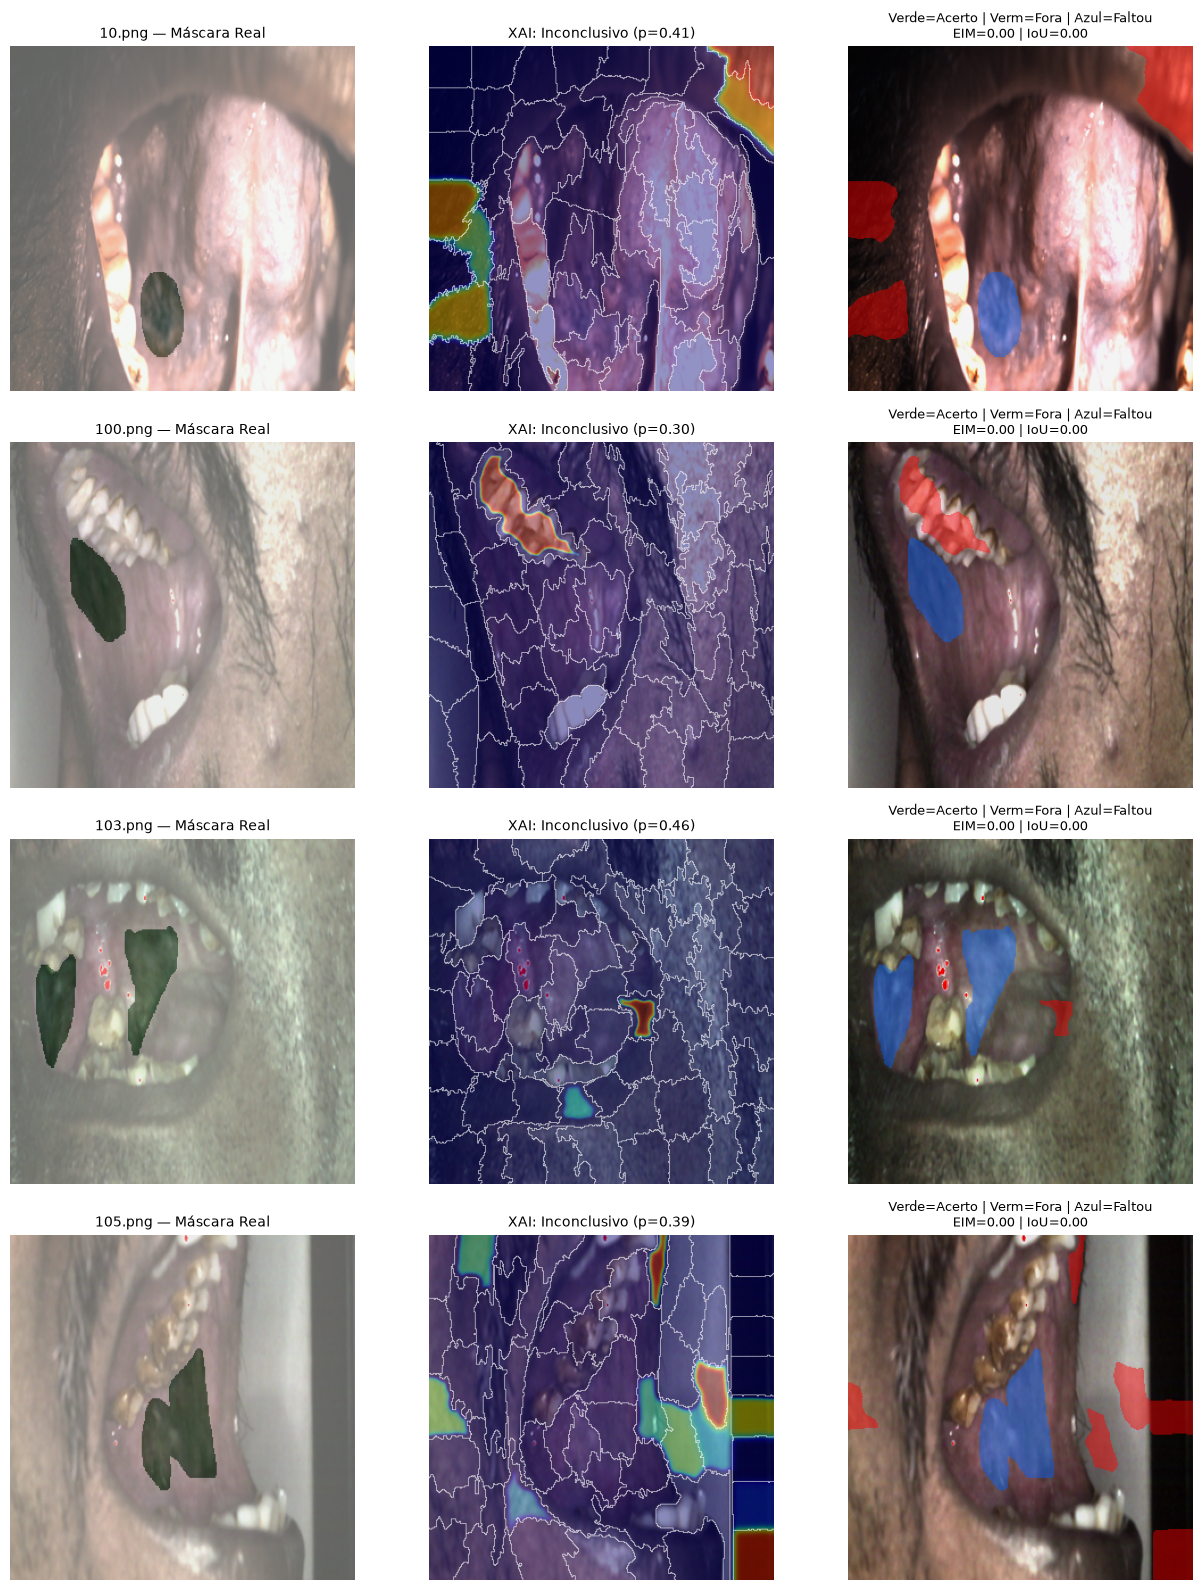

In [ ]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

PASTA_IMAGENS = Path("../data/dataset_mascaras/images")
PASTA_MASCARAS = Path("../data/dataset_mascaras/masks")

imgs = sorted(PASTA_IMAGENS.glob("*.png"))
masks = sorted(PASTA_MASCARAS.glob("*.png"))
mapa_mascaras = {p.stem: p for p in masks}
pares = [(p, mapa_mascaras[p.stem]) for p in imgs if p.stem in mapa_mascaras]

print(f"images/: {len(imgs)} | masks/: {len(masks)} | Pares exatos: {len(pares)}")
assert len(pares) > 0, "Nenhum par encontrado."

# Checa os valores reais da primeira máscara (0/1 vs 0/255)
m0 = np.asarray(Image.open(pares[0][1]).convert("L"))
print("Valores únicos na 1ª máscara:", np.unique(m0)[:10])

# Se quiser um teste rápido antes de rodar nos 185, troque None por 50
MAX_IMAGENS = None
pares_eval = pares[:MAX_IMAGENS] if MAX_IMAGENS else pares

device_eval = "cuda" if torch.cuda.is_available() else "cpu"
num_samples_eval = 150 if device_eval == "cuda" else 80
print(f"Executando em {device_eval} | {len(pares_eval)} imagens | num_samples={num_samples_eval}")

import importlib
import src.explainability
importlib.reload(src.explainability)

explainer_dryad = src.explainability.SuperpixelGraphExplainer(
    model=model,
    n_segments=70,
    compactness=10,
    num_samples=num_samples_eval,
    t_baixo=t_baixo,
    t_alto=t_alto,
    device=device_eval,
)

W, H = explainer_dryad.input_width, explainer_dryad.input_height
LIMIAR_HMAP = 0.5

registros = []
exemplos_plot = []
t0 = time.time()

for idx, (img_path, mask_path) in enumerate(pares_eval, 1):
    img = Image.open(img_path).convert("RGB")
    img_res = img.resize((W, H))

    mask_img = Image.open(mask_path).convert("L").resize((W, H), Image.NEAREST)
    mask_bin = np.asarray(mask_img) > 0  # funciona para máscaras 0/1 e 0/255

    if not np.any(mask_bin):
        continue

    res = explainer_dryad.explain(img, seed=42)
    hmap = res["heatmap"]
    energia_total = float(hmap.sum())

    # 1. Métricas contínuas
    if energia_total > 0:
        eim = float(hmap[mask_bin].sum() / energia_total)
        pico_y, pico_x = np.unravel_index(np.argmax(hmap), hmap.shape)
        pointing_hit = int(mask_bin[pico_y, pico_x])
    else:
        eim, pointing_hit = 0.0, 0

    area_lesao = float(mask_bin.mean())
    razao_foco = eim / area_lesao if area_lesao > 0 else 0.0

    # 2. Métricas pixel a pixel (heatmap >= LIMIAR_HMAP vs máscara)
    pred_bin = hmap >= LIMIAR_HMAP
    vp = pred_bin & mask_bin
    fp = pred_bin & (~mask_bin)
    fn = (~pred_bin) & mask_bin

    inter = int(vp.sum())
    uniao = int((pred_bin | mask_bin).sum())
    iou = inter / uniao if uniao > 0 else 0.0
    dice = (2 * inter) / (int(pred_bin.sum()) + int(mask_bin.sum())) if (pred_bin.sum() + mask_bin.sum()) > 0 else 0.0
    prec_esp = inter / int(pred_bin.sum()) if pred_bin.sum() > 0 else 0.0
    rec_esp = inter / int(mask_bin.sum()) if mask_bin.sum() > 0 else 0.0

    registros.append({
        "arquivo": img_path.name,
        "probabilidade": round(res["probabilidade"], 4),
        "classificacao": res["classificacao"],
        "drop_top5": round(res["fidelity_drop_top5"], 4),
        "area_lesao": round(area_lesao, 4),
        "EIM": round(eim, 4),
        "razao_foco": round(razao_foco, 2),
        "pointing_hit": pointing_hit,
        "IoU": round(iou, 4),
        "Dice": round(dice, 4),
        "Prec_Espacial": round(prec_esp, 4),
        "Rec_Espacial": round(rec_esp, 4),
    })

    # Guarda 4 exemplos previstos como suspeita (Maligno/Inconclusivo) para o gráfico
    if len(exemplos_plot) < 4 and res["classificacao"] != "Benigno":
        base = np.asarray(img_res, dtype=np.float32) / 255.0
        mapa_rgb = np.zeros_like(base)
        mapa_rgb[vp] = [0.0, 1.0, 0.0]   # Verde: XAI acertou a ferida
        mapa_rgb[fp] = [1.0, 0.0, 0.0]   # Vermelho: XAI destacou fora
        mapa_rgb[fn] = [0.0, 0.4, 1.0]   # Azul: ferida não destacada
        tem_cor = vp | fp | fn
        vis = base.copy()
        vis[tem_cor] = 0.55 * base[tem_cor] + 0.45 * mapa_rgb[tem_cor]
        vis_uint8 = (np.clip(vis, 0, 1) * 255).astype(np.uint8)
        exemplos_plot.append((img_path.name, img_res, mask_bin, res, vis_uint8, eim, iou))

    if idx % 10 == 0 or idx == len(pares_eval):
        elapsed = time.time() - t0
        eta = (elapsed / idx) * (len(pares_eval) - idx)
        print(f"[{idx}/{len(pares_eval)}] {elapsed:.0f}s decorridos | ETA: {eta:.0f}s")

df_mascaras = pd.DataFrame(registros)
display(df_mascaras.head(10))

def resumir_xai(df, titulo):
    if len(df) == 0:
        print(f"\n=== {titulo}: 0 amostras ===")
        return
    print(f"\n=== {titulo} (N={len(df)}) ===")
    print(f"EIM médio:            {df['EIM'].mean():.4f} ± {df['EIM'].std():.4f}")
    print(f"Razão de Foco média:  {df['razao_foco'].mean():.2f}x (>1.0 = acima do acaso)")
    print(f"Pointing Game:        {100 * df['pointing_hit'].mean():.1f}%")
    print(f"IoU / Dice médios:    {df['IoU'].mean():.4f} / {df['Dice'].mean():.4f}")
    print(f"Precisão / Recall:    {df['Prec_Espacial'].mean():.4f} / {df['Rec_Espacial'].mean():.4f}")
    print(f"Drop Top-5 médio:     {df['drop_top5'].mean():.4f}")

print("\nDistribuição de predições no Dryad:")
print(df_mascaras["classificacao"].value_counts())

resumir_xai(df_mascaras, "Todas as imagens com máscara")
resumir_xai(df_mascaras[df_mascaras["classificacao"] != "Benigno"], "Apenas Maligno / Inconclusivo (evidência de malignidade)")

# Painel visual (3 colunas) pronto para o Overleaf
if len(exemplos_plot) > 0:
    fig, axes = plt.subplots(len(exemplos_plot), 3, figsize=(13, 4 * len(exemplos_plot)))
    if len(exemplos_plot) == 1:
        axes = np.array([axes])

    for i, (nome, img_res, mask_bin, res, vis_uint8, eim, iou) in enumerate(exemplos_plot):
        axes[i, 0].imshow(img_res)
        axes[i, 0].imshow(mask_bin, cmap="Greens", alpha=0.4)
        axes[i, 0].set_title(f"{nome} — Máscara Real", fontsize=10)

        axes[i, 1].imshow(res["overlay_image"])
        axes[i, 1].set_title(f"XAI: {res['classificacao']} (p={res['probabilidade']:.2f})", fontsize=10)

        axes[i, 2].imshow(vis_uint8)
        axes[i, 2].set_title(f"Verde=Acerto | Verm=Fora | Azul=Faltou\nEIM={eim:.2f} | IoU={iou:.2f}", fontsize=9)

        for j in range(3):
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.savefig("validacao_xai_mascaras.png", dpi=200, bbox_inches="tight")
    plt.show()

In [20]:
# df_mascaras = pd.DataFrame(registros)
# df_mascaras.to_csv("resultados_dryad_xai.csv", index=False)
# display(df_mascaras.head(10))
df_mascaras = pd.read_csv('resultados_dryad_xai.csv')

In [21]:
top_acertos = df_mascaras[df_mascaras["classificacao"] != "Benigno"].nlargest(2, "EIM")["arquivo"].tolist()
selecionados = top_acertos + ["100.png", "105.png"]
print("Selecionados para o painel contrastivo:", selecionados)

Selecionados para o painel contrastivo: ['14.png', '198.png', '100.png', '105.png']


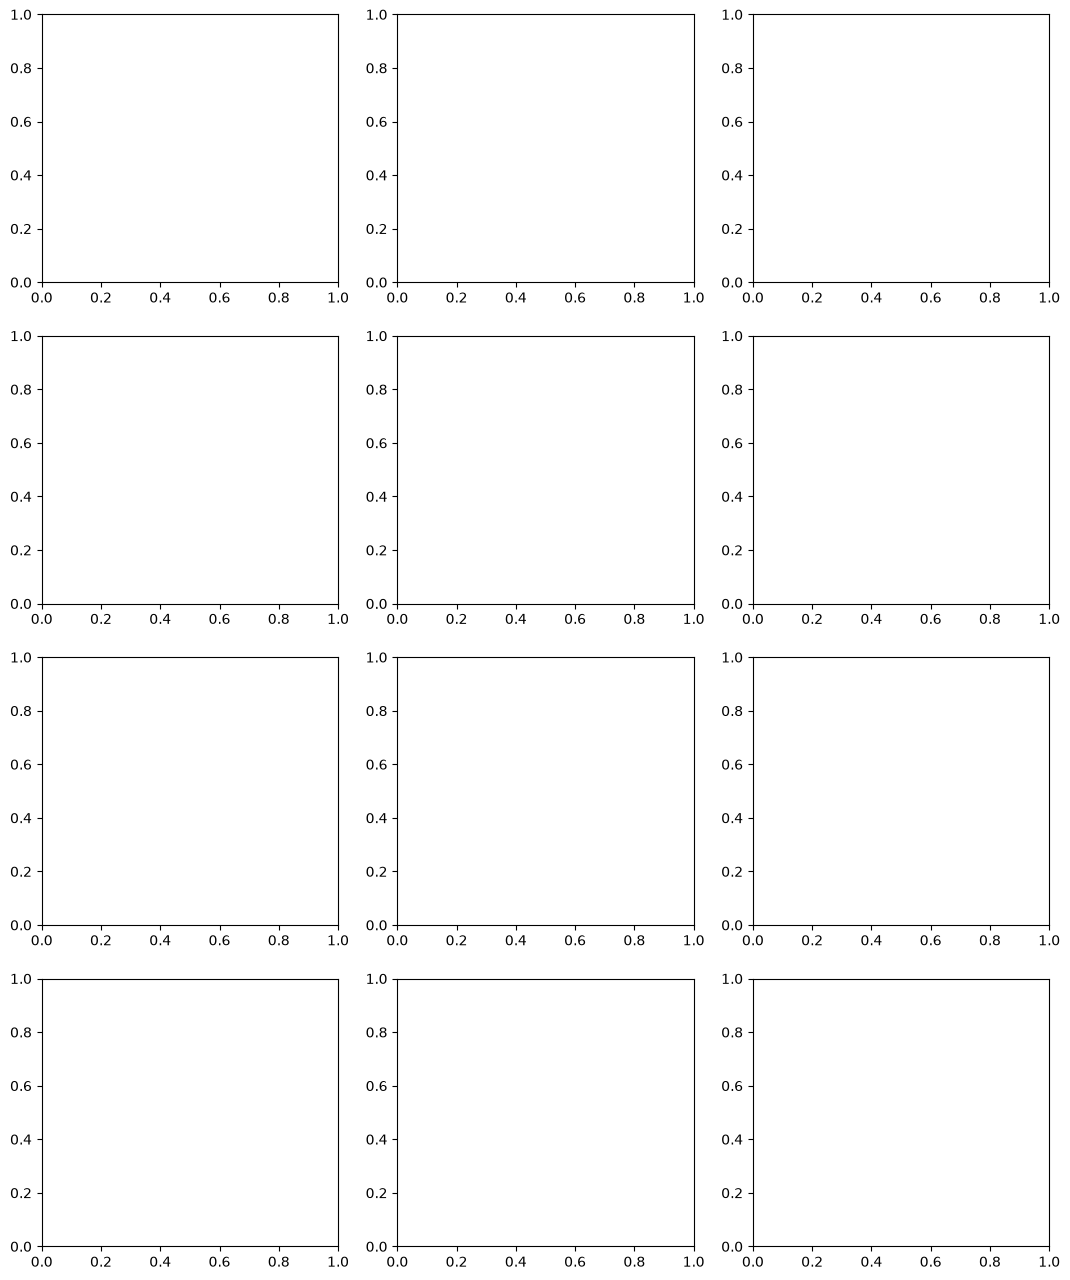

In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PASTA_IMAGENS = Path("../data/dataset_mascaras/images")
PASTA_MASCARAS = Path("../data/dataset_mascaras/masks")

selecionados = ["14.png", "198.png", "100.png", "105.png"]
W, H = explainer_dryad.input_width, explainer_dryad.input_height
LIMIAR_HMAP = 0.5

fig, axes = plt.subplots(len(selecionados), 3, figsize=(13, 4 * len(selecionados)))

for i, nome in enumerate(selecionados):
    img_path = PASTA_IMAGENS / nome
    mask_path = PASTA_MASCARAS / nome

    img = Image.open(img_path).convert("RGB")
    img_res = img.resize((W, H))
    mask_bin = np.asarray(Image.open(mask_path).convert("L").resize((W, H), Image.NEAREST)) > 0

    res = explainer_dryad.explain(img, seed=42)
    hmap = res["heatmap"]
    energia_total = float(hmap.sum())
    eim = float(hmap[mask_bin].sum() / energia_total) if energia_total > 0 else 0.0

    pred_bin = hmap >= LIMIAR_HMAP
    vp = pred_bin & mask_bin
    fp = pred_bin & (~mask_bin)
    fn = (~pred_bin) & mask_bin
    inter = int(vp.sum())
    uniao = int((pred_bin | mask_bin).sum())
    iou = inter / uniao if uniao > 0 else 0.0

    base = np.asarray(img_res, dtype=np.float32) / 255.0
    mapa_rgb = np.zeros_like(base)
    mapa_rgb[vp] = [0.0, 1.0, 0.0]   # Verde: acerto na lesão
    mapa_rgb

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PASTA_IMAGENS = Path("../data/dataset_mascaras/images")
PASTA_MASCARAS = Path("../data/dataset_mascaras/masks")

selecionados = ["14.png", "198.png", "100.png", "105.png"]
W, H = explainer_dryad.input_width, explainer_dryad.input_height
LIMIAR_HMAP = 0.5

dados_plot = []

for i, nome in enumerate(selecionados):
    img_path = PASTA_IMAGENS / nome
    mask_path = PASTA_MASCARAS / nome
    assert img_path.exists(), f"Imagem não encontrada: {img_path}"
    assert mask_path.exists(), f"Máscara não encontrada: {mask_path}"

    img = Image.open(img_path).convert("RGB")
    res = explainer_dryad.explain(img, seed=42)

    hmap = np.asarray(res["heatmap"], dtype=np.float32)
    h_map, w_map = hmap.shape[:2]

    img_res = img.resize((w_map, h_map))
    mask_bin = np.asarray(
        Image.open(mask_path).convert("L").resize((w_map, h_map), Image.NEAREST)
    ) > 0

    energia_total = float(hmap.sum())
    eim = float(hmap[mask_bin].sum() / energia_total) if energia_total > 0 else 0.0

    pred_bin = hmap >= LIMIAR_HMAP
    vp = pred_bin & mask_bin
    fp = pred_bin & (~mask_bin)
    fn = (~pred_bin) & mask_bin
    inter = int(vp.sum())
    uniao = int((pred_bin | mask_bin).sum())
    iou = inter / uniao if uniao > 0 else 0.0

    base = np.asarray(img_res, dtype=np.float32) / 255.0
    mapa_rgb = np.zeros_like(base)
    mapa_rgb[vp] = [0.0, 1.0, 0.0]
    mapa_rgb[fp] = [1.0, 0.0, 0.0]
    mapa_rgb[fn] = [0.0, 0.4, 1.0]

    tem_cor = vp | fp | fn
    vis = base.copy()
    vis[tem_cor] = 0.55 * base[tem_cor] + 0.45 * mapa_rgb[tem_cor]
    vis_uint8 = (np.clip(vis, 0, 1) * 255).astype(np.uint8)

    ov_arr = np.asarray(res["overlay_image"], dtype=np.uint8)
    if ov_arr.ndim == 3 and ov_arr.shape[2] == 4:
        ov_arr = ov_arr[:, :, :3]

    rotulo = "Maior EIM" if i < 2 else "Atalho espúrio"
    dados_plot.append((nome, rotulo, img_res, mask_bin, ov_arr, res, vis_uint8, eim, iou))

# Só monta a figura depois de tudo calculado sem erro
fig, axes = plt.subplots(len(dados_plot), 3, figsize=(13, 4 * len(dados_plot)))

for i, (nome, rotulo, img_res, mask_bin, ov_arr, res, vis_uint8, eim, iou) in enumerate(dados_plot):
    axes[i, 0].imshow(img_res)
    axes[i, 0].imshow(mask_bin, cmap="Greens", alpha=0.4)
    axes[i, 0].set_title(f"{nome} ({rotulo}) — Máscara Real", fontsize=10)

    axes[i, 1].imshow(ov_arr)
    axes[i, 1].set_title(f"XAI: {res['classificacao']} (p={res['probabilidade']:.2f})", fontsize=10)

    axes[i, 2].imshow(vis_uint8)
    axes[i, 2].set_title(f"Verde=Acerto | Verm=Fora | Azul=Faltou\nEIM={eim:.2f} | IoU={iou:.2f}", fontsize=9)

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("validacao_xai_mascaras_contrastivo.png", dpi=200, bbox_inches="tight")
plt.show()